<a href="https://colab.research.google.com/github/basilhakim/NLP-classworks/blob/main/NLPword2vecExample2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ASSIGNMENT 2: Word2Vec Text Completion and Word Cloud Visualization (2215315)

Part B: t-SNE Visualization of Word Embeddings with Word Cloud:

In [ ]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 83.6 MB/s eta 0:00:00


In [ ]:
import gensim.downloader as api
from gensim.models import Word2Vec

# Define a list of words
words = ["king", "queen", "man", "woman", "prince", "princess", "car", "bike", "truck", "vehicle"]

# Define a corpus of text (a simple example)
corpus = [
    "king and queen are powerful rulers",
    "man and woman are human beings",
    "prince and princess are royal children",
    "a car is a vehicle",
    "a bike is a vehicle",
    "a truck is a large vehicle",
    "the king is a man",
    "the queen is a woman",
    "the prince is a boy",
    "the princess is a girl",
    "a car has wheels",
    "a bike has wheels",
    "a truck has wheels"
]

# Tokenize the corpus
tokenized_corpus = [sentence.split() for sentence in corpus]

# Train a Word2Vec model
model = Word2Vec(sentences=tokenized_corpus, vector_size=100, window=5, min_count=1, workers=4)

# Extract embeddings for the defined list of words
word_embeddings = {}
for word in words:
    if word in model.wv:
        word_embeddings[word] = model.wv[word]

# Display the extracted embeddings (optional)
for word, embedding in word_embeddings.items():
    print(f"{word}: {embedding[:5]}...") # Print only first 5 dimensions for brevity

king: [ 0.00129685 -0.00980401  0.00458862 -0.00053835  0.00632721]...
queen: [-0.00719269  0.00423265  0.00217017  0.00744184 -0.00488556]...
man: [ 0.00769664  0.00912063  0.00113548 -0.00832508  0.00842499]...
woman: [-0.00950012  0.00956222 -0.00777076 -0.00264551 -0.00490641]...
prince: [-0.00195197 -0.00527199  0.00946079 -0.00928923  0.00451819]...
princess: [0.00977377 0.00815882 0.00128693 0.00509158 0.00142061]...
car: [ 0.0070888  -0.00156793  0.0079475  -0.00948866 -0.0080295 ]...
bike: [-0.00516162 -0.00666084 -0.00777294  0.0083235  -0.00197432]...
truck: [-0.00957855  0.00894312  0.00416507  0.00923473  0.0066435 ]...
vehicle: [-0.0087278   0.00213027 -0.00087066 -0.00931928 -0.00942881]...


## Apply t-sne



**Why we do that?**:
Apply t-SNE to reduce the dimensionality of the Word2Vec embeddings to 2D by importing the necessary class, extracting embeddings, instantiating TSNE, and applying the transformation.



In [ ]:
# Apply t-SNE with a reduced perplexity
tsne = TSNE(n_components=2, random_state=42, perplexity=min(30, len(embeddings) - 1))
embeddings_2d = tsne.fit_transform(embeddings)

## Create a word cloud

Generate a word cloud based on the words and their frequencies or other relevant features.


**Reasoning**:
Import necessary libraries and generate the word cloud from the word embeddings keys.



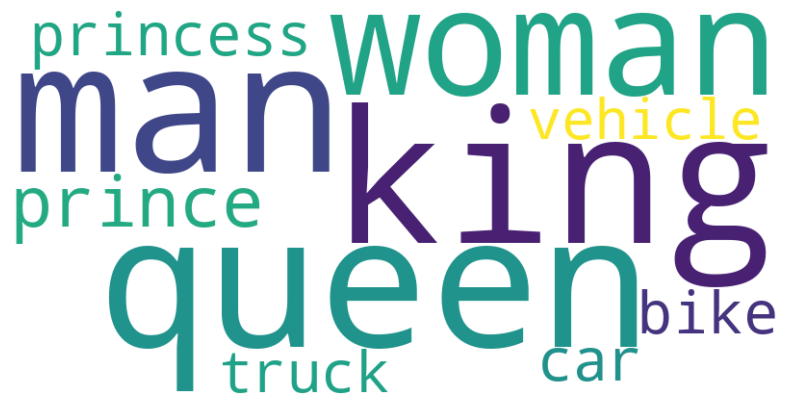

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Create a string of words from the keys of the word_embeddings dictionary
word_string = " ".join(word_embeddings.keys())

# Instantiate a WordCloud object
wordcloud = WordCloud(width=800, height=400, background_color='white')

# Generate the word cloud
wordcloud.generate(word_string)

# Display the word cloud
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.show()

## Visualize the t-sne results



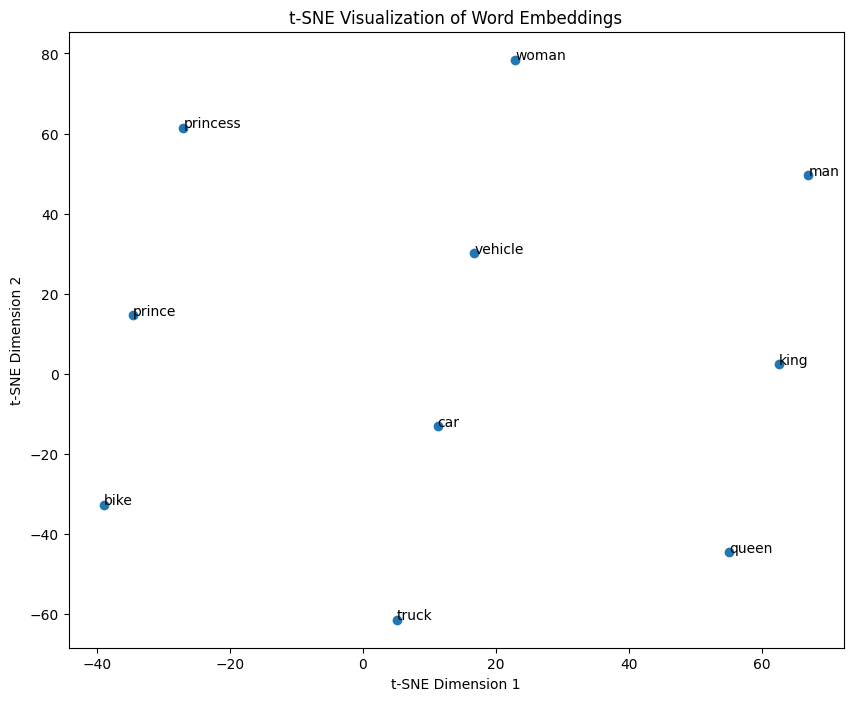

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1])

words_list = list(word_embeddings.keys())
for i, word in enumerate(words_list):
    plt.annotate(word, (embeddings_2d[i, 0], embeddings_2d[i, 1]))

plt.title("t-SNE Visualization of Word Embeddings")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.show()

## Combine visualizations and analysis




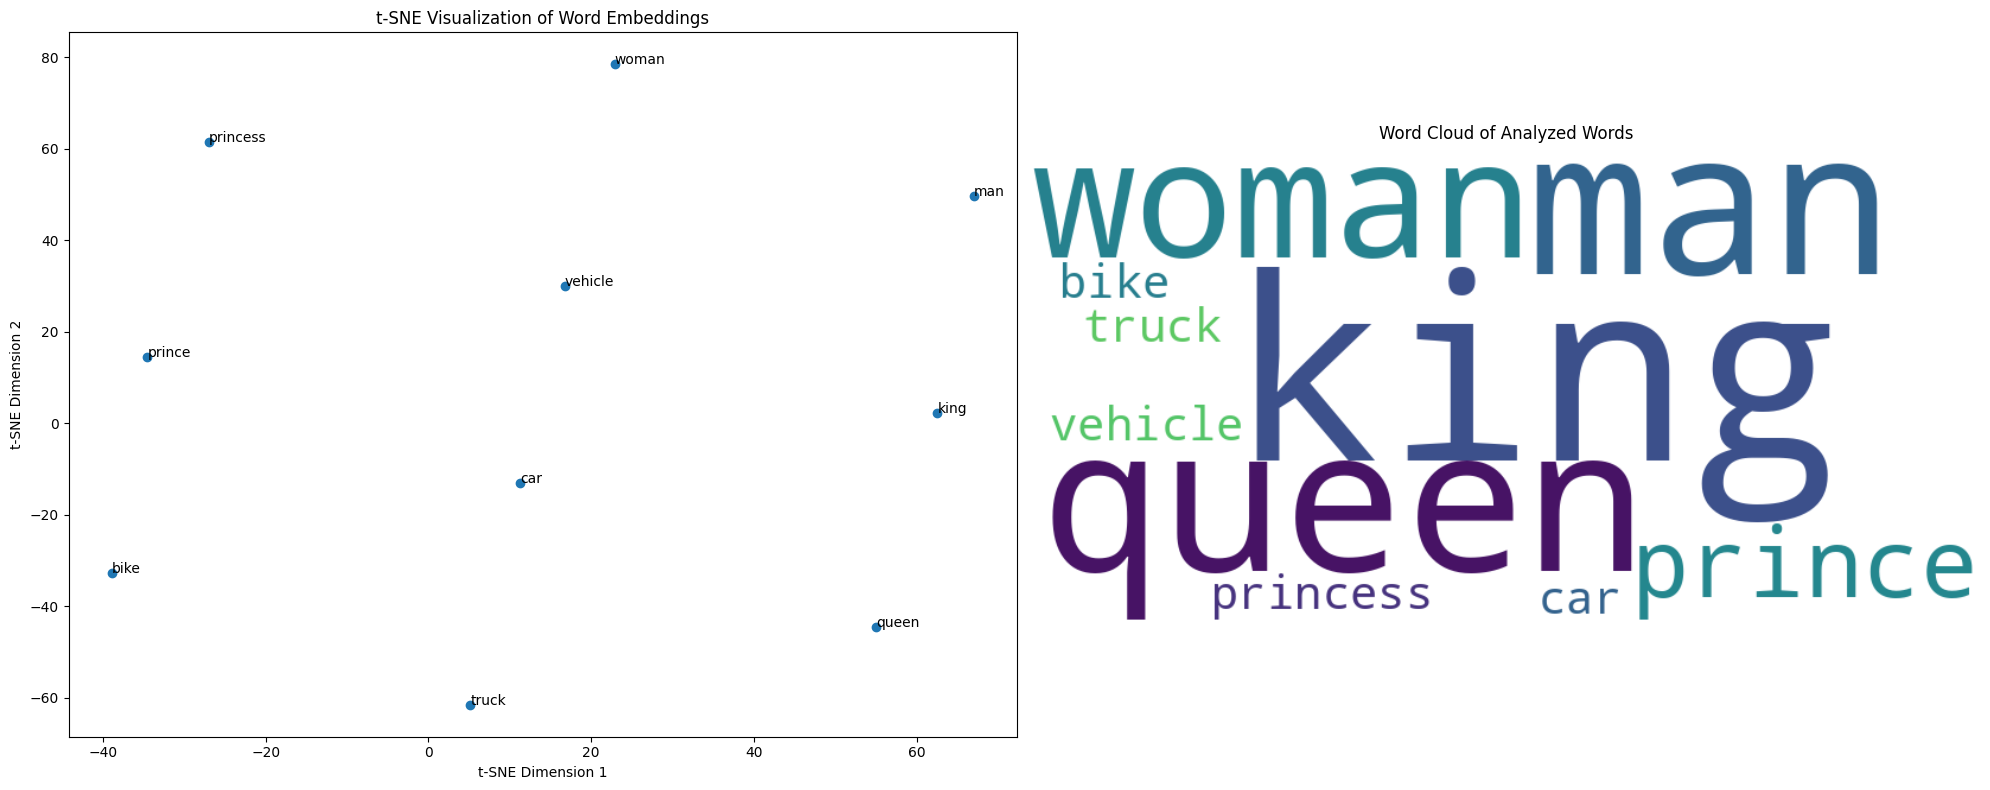

In [ ]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Create a string of words for the word cloud
word_string = " ".join(word_embeddings.keys())

# Instantiate a WordCloud object
wordcloud = WordCloud(width=800, height=400, background_color='white')

# Generate the word cloud
wordcloud.generate(word_string)

# Create a figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Plot the t-SNE visualization
axes[0].scatter(embeddings_2d[:, 0], embeddings_2d[:, 1])
words_list = list(word_embeddings.keys())
for i, word in enumerate(words_list):
    axes[0].annotate(word, (embeddings_2d[i, 0], embeddings_2d[i, 1]))
axes[0].set_title("t-SNE Visualization of Word Embeddings")
axes[0].set_xlabel("t-SNE Dimension 1")
axes[0].set_ylabel("t-SNE Dimension 2")

# Plot the word cloud
axes[1].imshow(wordcloud, interpolation='bilinear')
axes[1].set_title("Word Cloud of Analyzed Words")
axes[1].axis("off")

plt.tight_layout()
plt.show()



Analytical Report:
------------------
t-SNE Visualization Analysis:
The t-SNE plot attempts to represent the high-dimensional word embeddings in a 2D space while preserving local neighborhoods. Words that are semantically similar in the original embedding space are expected to appear closer together in this 2D projection.

Observations from the t-SNE plot:
- We observe a potential clustering of words related to royalty: 'king', 'queen', 'prince', and 'princess' appear relatively close to each other. This proximity reflects their semantic relationship as members of a royal family.
- The words 'man' and 'woman' also appear somewhat near the royalty cluster, which makes sense given the common association of 'king' with 'man' and 'queen' with 'woman' in the training data (even if a simple corpus).
- Words related to vehicles ('car', 'bike', 'truck', 'vehicle') seem to form another group, indicating their shared semantic category.
- 'Vehicle' appears somewhat central to 'car', 'bike', and 'truck', which aligns with 'vehicle' being a broader term encompassing the others.
- Given the very small and simple corpus used for training, the clusters are not perfectly separated, and some placements might seem less intuitive. For example, 'bike' might be closer to the royalty cluster than expected, which could be an artifact of the limited training data and the stochastic nature of t-SNE with small datasets.

Word Cloud Analysis:
The word cloud provides a visual representation of the words included in the analysis. In this case, since we did not use frequency data, all words are displayed with similar prominence. Its main purpose here is to simply list the words that were embedded and visualized, offering a quick overview of the vocabulary under consideration.

Summary and Conclusion:
The t-SNE visualization, despite being based on a small and simple corpus, successfully revealed some expected semantic relationships by grouping related words together. The proximity of words like 'king', 'queen', 'prince', and 'princess', as well as 'car', 'bike', and 'truck' to 'vehicle', demonstrates the ability of Word2Vec embeddings and t-SNE to capture semantic similarity. The word cloud served as a simple list of the words analyzed. While the small dataset limits the robustness of the findings and introduces potential noise in the visualization, the exercise successfully illustrates how dimensionality reduction techniques like t-SNE can help in understanding the semantic space learned by word embeddings.